In [1]:
import os
import cv2
import json
import keras
import random
import numpy as np
from glob import glob
from natsort import natsorted
from keras.models import Model
from keras import backend as K
import tensorflow as tf
import matplotlib.pyplot as plt
from IPython.display import Image as ShowImage
from KerasModels import Easter2, Easter2b
from Modules import PatchedPerigLayoutDetection, PatchedLineDetection, OCRInference, KerasInference
from Utils import rotate_from_hough, get_line_images_from_line_data
print(tf.__version__)
print(keras.__version__)




2.15.0
2.15.0


In [17]:
def show_image(image: np.array, cmap: str = "") -> None:
    plt.figure(figsize=(24, 13))
    #plt.axis("off")
    
    if cmap != "":
        plt.imshow(image, cmap=cmap)
    else:
        plt.imshow(image)


def get_charset(characters: str):
    """
    To be used when reading a charset from a config file
    """
    characters = [c for c in characters]
    characters.append("[BLK]")
    characters.insert(0, "[UNK]")

    return characters

def get_random_color():
    rand_r = random.randint(40, 255)
    rand_g = random.randint(40, 200)
    rand_b = random.randint(40, 220)
    color = (rand_r, rand_g, rand_b)

    return color

In [3]:
#inference_model = Model(model.get_layer("images").input, model.get_layer("Final").output)
#keras_model =  keras.saving.load_model("Models/OCRModels/GlomanThang/2024_1_22_15_34/GlomanThang_easter2b.keras", safe_mode=False, custom_objects={"K": K})

layout_config = "Models\LayoutModels\LA_v2_2024-1-22_6-36\model_config.json"
layout_inference = PatchedPerigLayoutDetection(layout_config)

line_model_config = "Models/LineModels/line_model_config.json"
line_inference = PatchedLineDetection(config_file=line_model_config, binarize_output=False, mode="cuda")

d:\Github\OCR-Inference\venv\lib\site-packages\onnxruntime\capi\onnxruntime_inference_collection.py:69: UserWarning: Specified provider 'CUDAExecutionProvider' is not in available provider names.Available providers: 'AzureExecutionProvider, CPUExecutionProvider'
  warnings.warn(


Assuming model path: Models\LineModels
Line Inference -> Init(): True


Test images: 1126


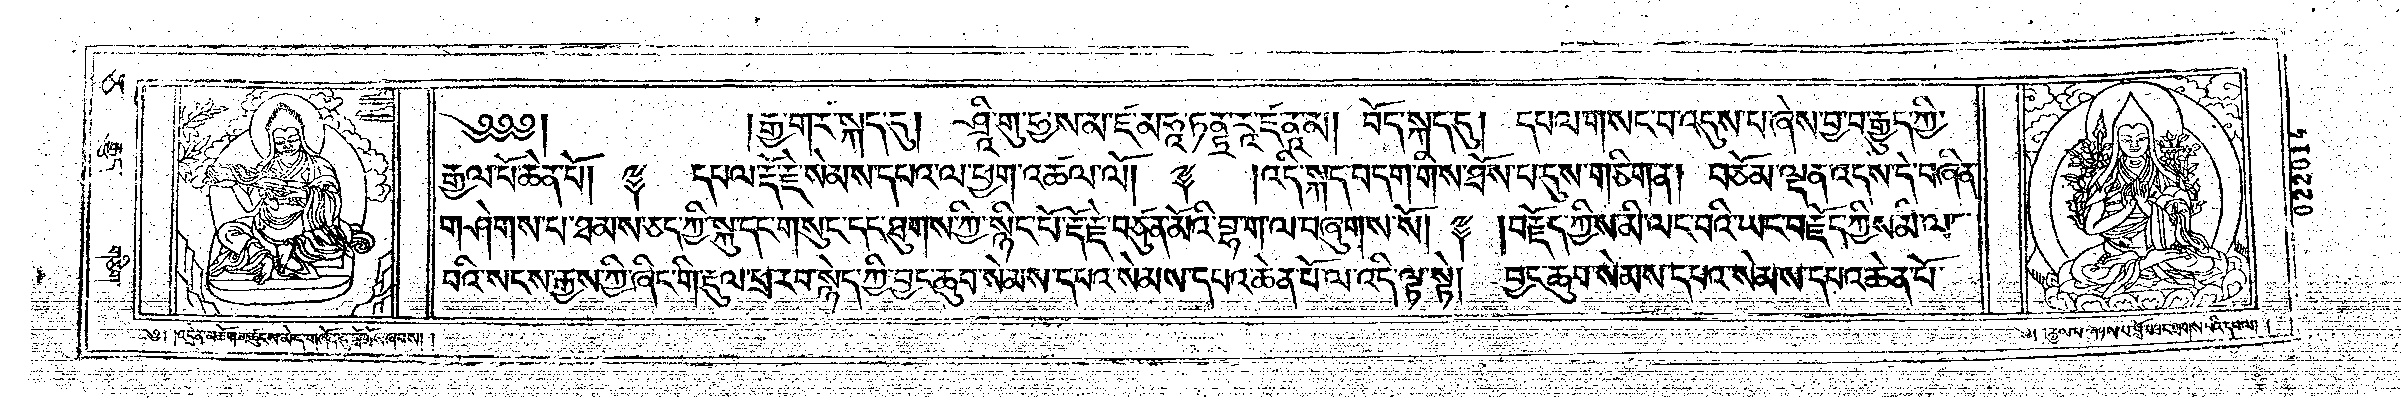

In [33]:
data_root = "D:\Datasets\Tibetan\OCR\W22272"
test_set = "W22272-v5"
images = natsorted(glob(f"{os.path.join(data_root, test_set)}/*.jpg"))

print(f"Test images: {len(images)}")

img_idx = 5
ShowImage(images[img_idx])

Test images: 548


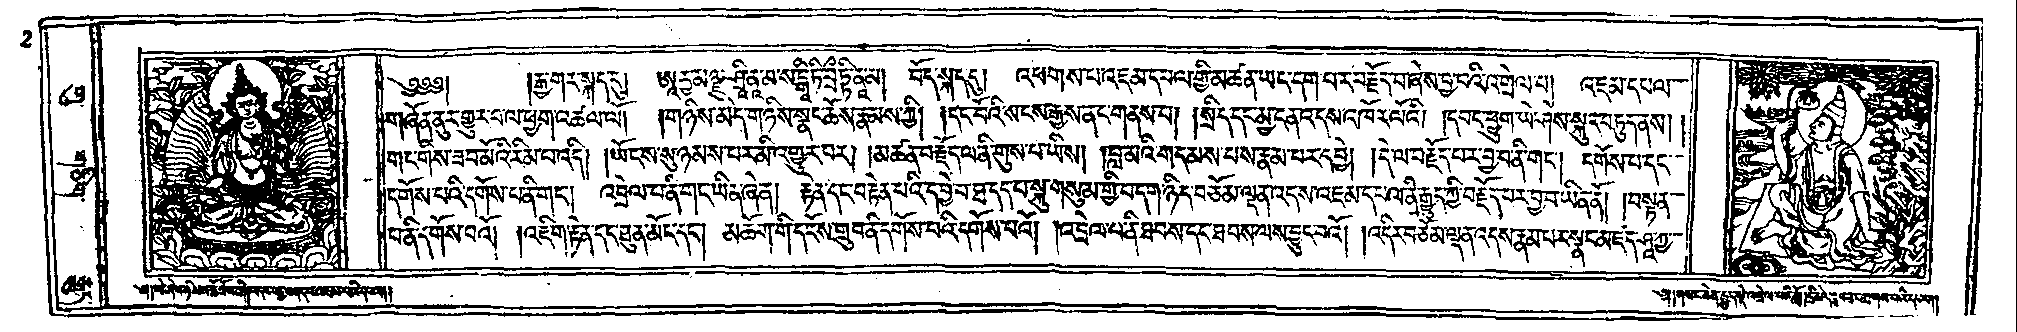

In [41]:
data_root = "Data"
test_set = "W23703/I1380" # Derge Tenjur
#test_set = "W22106/I1KG11830" # Buston gsung 'bum
images = natsorted(glob(f"{os.path.join(data_root, test_set)}/*.jpg"))

print(f"Test images: {len(images)}")

img_idx = 0
ShowImage(images[img_idx])

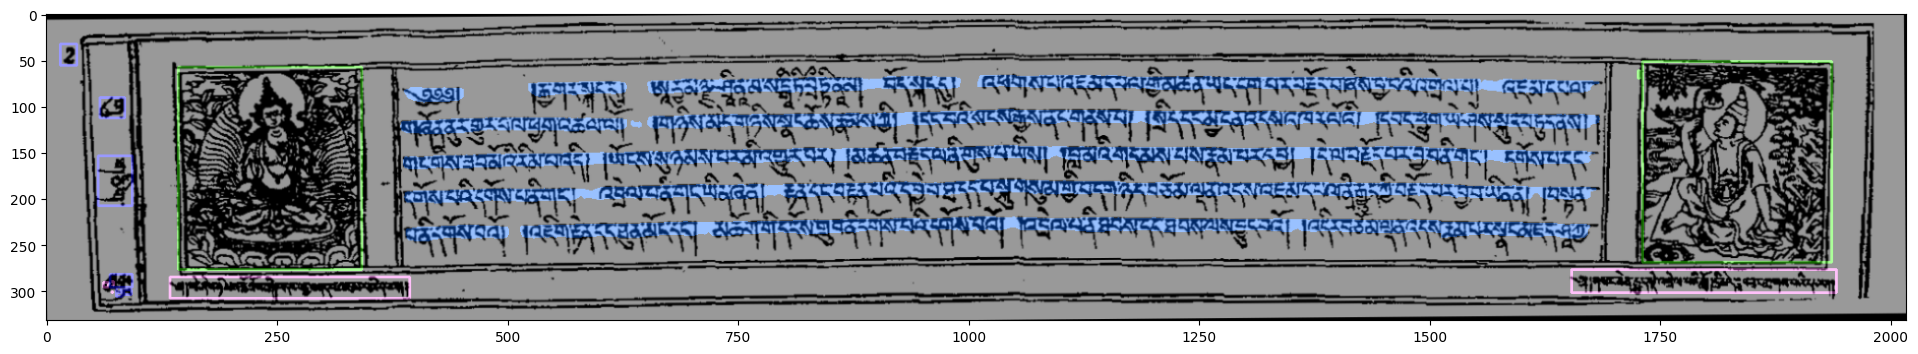

In [42]:
# layout_inference
try:
  image_name = os.path.basename(images[img_idx]).split(".")[0]
  _img = cv2.imread(images[img_idx])

except FileExistsError as e:
    print.error(f"Cant read file at provided location: {images[img_idx]}, {e}")

# layout_inference
layout_data, preview_img = layout_inference.predict(_img)
show_image(preview_img)

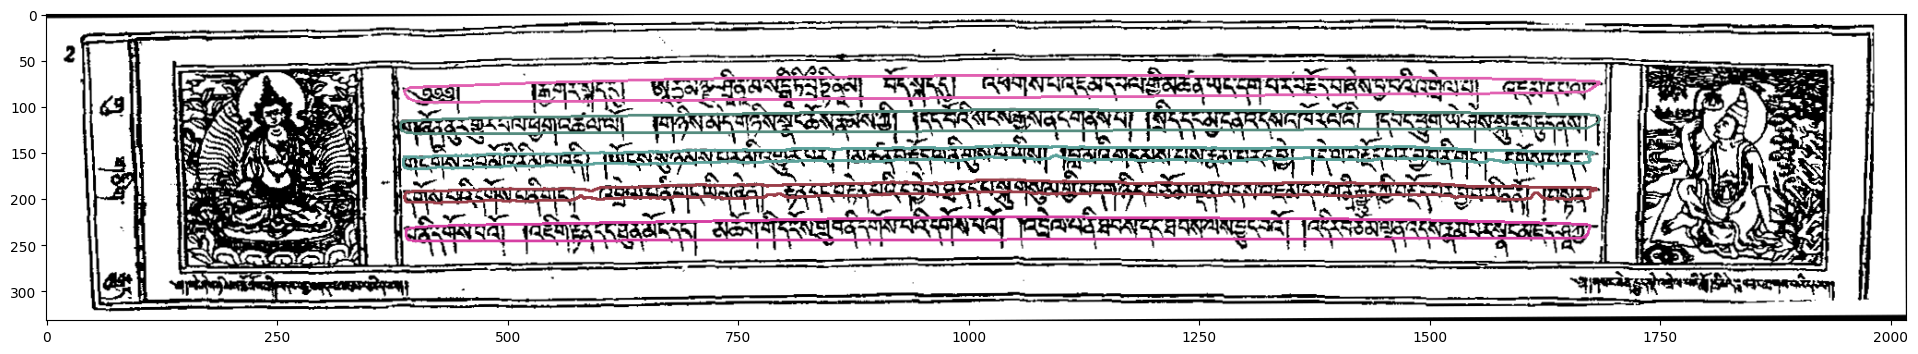

In [43]:
sorted_layout_data = layout_inference.sort_lines(layout_data)

p_img, angle = rotate_from_hough(_img)
prev_img = p_img.copy()
color = get_random_color()

for line_data in layout_data.lines:
    color = get_random_color()
    cv2.drawContours(prev_img,[line_data.contour],contourIdx=-1,color=color,thickness=2)

show_image(prev_img) 

In [44]:
layout_line_images = get_line_images_from_line_data(p_img, sorted_layout_data.lines, dilate_kernel=32)

#### preview lines

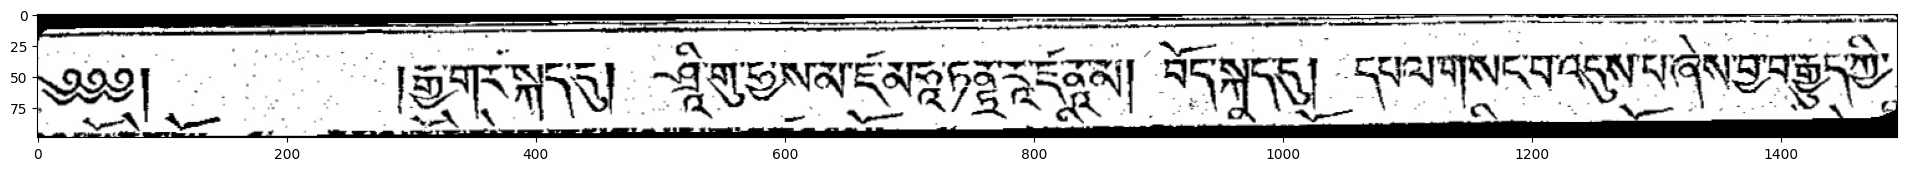

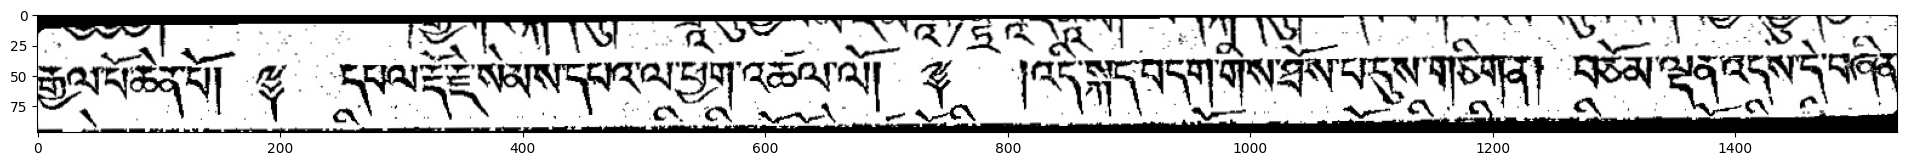

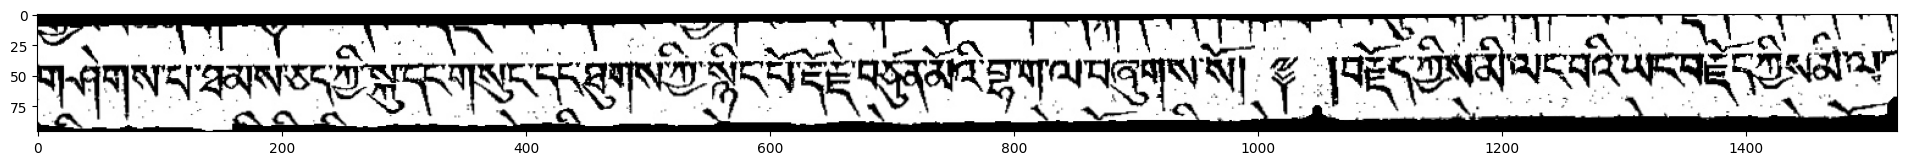

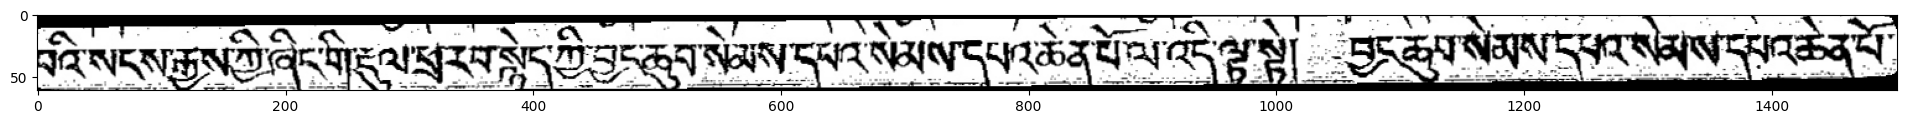

In [31]:
for idx, img in enumerate(layout_line_images):
    show_image(layout_line_images[idx])

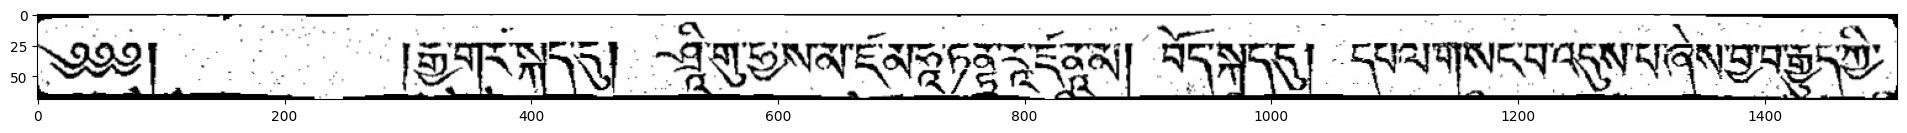

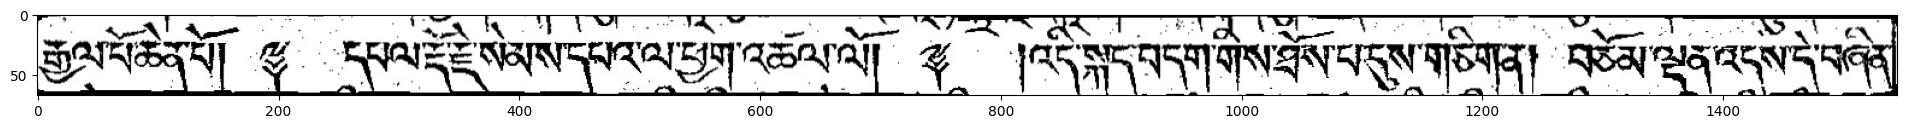

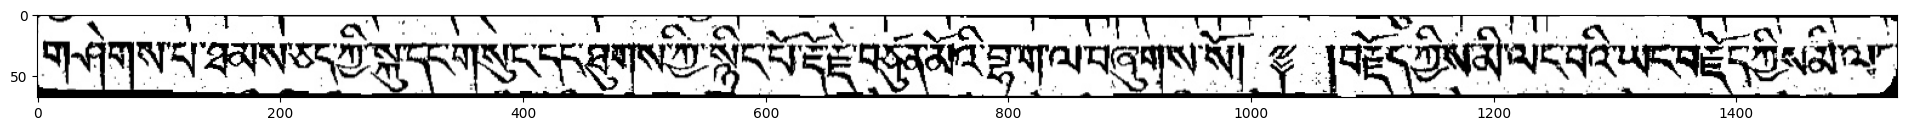

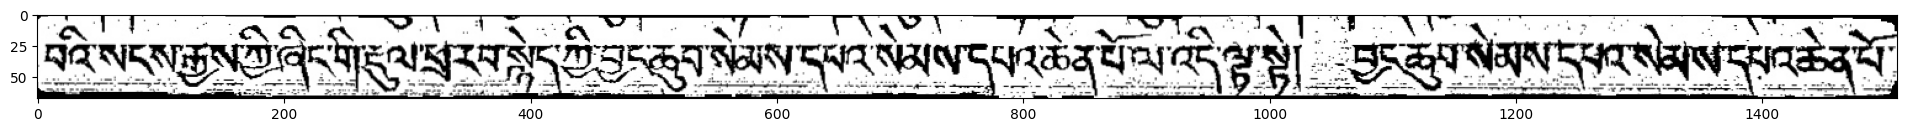

In [32]:
back_sized_image, rotated_image, line_images, sorted_contours, bbox, peaks = line_inference.predict(_img, 0, line_kernel=18)


for idx, img in enumerate(line_images):
    show_image(line_images[idx])

#### Keras Inference

In [45]:
keras_model_config = "Models/OCRModels/DergeTenjur/November2023_v2/model_config.json"
keras_inf = KerasInference(keras_model_config)

ocr_prediction = keras_inf.run(layout_line_images)

for line in ocr_prediction:
    print(line)

Loading Easter2
Y_pred: KerasTensor(type_spec=TensorSpec(shape=(None, 500, 73), dtype=tf.float32, name=None), name='Final/Softmax:0', description="created by layer 'Final'")
3
(5, 2000, 80)
རྒྱ་གར་སྐད་དུ།ཨཱ་ཀྱོ་ལ་ཧཱུཾ་ཤྲཱི་ཡྶ་མ་ས་+ཧོ་བོ་བཻ་བྷོ་འོས།བད་སྐོད་དུ༎རེསོགས་པའི་དེ་ཡི་དཔལ་གྱི་མཚོནི་ཡང་དག་པར་བརྗོད་པ་ཞེས་བྱ་བའི་འགྲེལ་པ།འཇམ་དཔལ་
གཞོན་ནར་གྱུར་པ་ལ་ཕྱག་འཚལ་ལོ༎གཉིས་ཡོད་གཉིས་སྡིང་ཆེས་ནོམས་ཀྱི༎དངོ་པོའི་སོངས་གྱི་སོ་ཞིང་གཞེས་སོ༎སྲིད་དང་མྱོ་ངན་འདིས་འཁོར་ལའོ༎དབང་ཕྱུག་ཡེ་ཤེས་སྐར་བཏུད་ནས༎
གང་གིས་ཟབ་མོའི་རིམ་པ་འདི༎ཡོངས་སུ་ཉམས་པར་མི་འགྱུར་བར༎མཚན་བརྗོད་ལ་ནི་གུས་པ་ཡས༎བླ་མའི་གདམས་པས་རྣམ་པར་དབྱེ༎དེ་ལ་བརྗོད་པར་བྱ་བ་ནི་གང་།དགོས་པ་དང་
དགོས་པའི་དགོས་པ་ནི་གང་།འབྲེལ་པ་ནི་གང་ཡིན་ཞེ་ན།རྟེན་དང་བརྟེན་པའི་དབྱེ་བ་ཐ་དད་པ་སྐོ་གསུམ་གྱི་བདག་ཉིད་བཅོམ་ལྡན་འདས་འཇམ་དཔལ་ནི་རྒྱུད་ཀྱི་བརྗོད་པར་བྱ་བ་ཡིན་ནོ༎བསྟན་
པ་ནི་དགས་པའོ༎འཇིག་རྟོན་དང་ཐུན་མིང་དང་།མེ་ལོག་གི་དངོས་ཧྲུ་བོ་ནི་དགིས་པའི་དགས་སོའོ༎འབྲོལ་བཞི་བིབས་དོངོ་བི་བིས་ལས་བྱུང་བེའི༎འདིར་བཅོམ་ལྡན་འདས་རྣམ་པར་སྣང་མཛད་ཤཱཀྱ་


#### ONNX-OCR

In [54]:
import cv2
from Config import COLOR_DICT
from Utils import rotate_from_hough, binarize_line
from DataClasses import LineData

from IPython.display import Image as ShowImage

In [58]:
layout_line_images = get_line_images_from_line_data(p_img, sorted_layout_data.lines)

for idx, img in enumerate(layout_line_images):
    show_image(layout_line_images[idx])

ONNX Inference

In [21]:
from Utils import prepare_ocr_image, binarize_line
from fast_ctc_decode import viterbi_search, beam_search
import onnxruntime as ort

In [66]:
#ocr_model_config = "Models/OCRModels/LithangKanjur/2023_12_6_7_13/model_config.json"
#ocr_model_config = "Models/OCRModels/LhasaKanjurEaster/ocr_model_config.json"
#ocr_model_config = "Models/OCRModels/DergeTenjur/ocr_model_config.json"
ocr_model_config = "Models/OCRModels/LhasaKanjur/ocr_model_config.json"
_file = open(ocr_model_config, encoding="utf-8")
json_content = json.loads(_file.read())
onnx_model_file = json_content["gpu-model"]
input_width = json_content["input_width"]
input_height = json_content["input_height"]
input_layer = json_content["input_layer"]
output_layer = json_content["output_layer"]
squeeze_channel_dim = (True if json_content["squeeze_channel_dim"] == "yes" else False)
swap_hw = True if json_content["swap_hw"] == "yes" else False
characters = json_content["charset"]

print(onnx_model_file)
print(f"{len(characters)}: {characters}")

sess = ort.InferenceSession(onnx_model_file)

Models/OCRModels/LhasaKanjur/LhasaKanjur_gpu.onnx
75: ß !#%'()+-./0123456789:=?@ADHIMNRSTUWXY[\]_abcdefghijklmnoprstuwyz|~&äüö<>;


In [34]:
for input in sess.get_inputs():
    print(input.name)
    print(input.shape)

input
['batch_size', 1, 80, 2000]


In [46]:
from Utils import pad_image2

def prepare_tf_ocr_image(image: np.array, target_height: int = 80, target_width: int = 2000):
    tf_img = tf.image.resize_with_pad(image, target_height, target_width)
    tf_img = tf_img / 255.0
    
    tf_img = tf.transpose(tf_img, perm=[1, 0, 2])
    tf_img = tf.squeeze(tf_img)

    return tf_img.numpy()

def prepare_ocr_image_v2(
    line_image: np.array, target_width: int = 2000, target_height: int = 80
):
    if len(line_image.shape) > 2:
        line_image = cv2.cvtColor(line_image, cv2.COLOR_BGR2GRAY)

    image = pad_image2(
        line_image,
        target_width=target_width,
        target_height=target_height,
        padding="black",
    )

    image = image.reshape((1, target_height, target_width))
    #image = np.expand_dims(image, axis=-1)
    #image = image / 255
    image = (image / 127.5) - 1.0
    image = image.astype(np.float32)
    return image

In [266]:
img_batch = [binarize_line(x, adaptive=False) for x in line_images]

In [60]:
line_img_batch = [
            prepare_ocr_image_v2(
                x, target_width=input_width, target_height=input_height
            )
            for x in line_images
        ]


layout_img_batch = [prepare_ocr_image_v2(x, target_width=input_width, target_height=input_height) for x in layout_line_images]

In [61]:
line_img_batch = np.array(line_img_batch, np.float32)
layout_img_batch = np.array(layout_img_batch, np.float32)

In [62]:
print(line_img_batch.shape)
print(layout_img_batch.shape)

(7, 1, 80, 2000)
(7, 1, 80, 2000)


In [63]:
line_ort_batch = ort.OrtValue.ortvalue_from_numpy(line_img_batch)
layout_ort_batch = ort.OrtValue.ortvalue_from_numpy(layout_img_batch)

In [47]:
if squeeze_channel_dim:
    img_batch = np.squeeze(img_batch, axis=1)
if swap_hw:
    img_batch = np.transpose(img_batch, axes=[0, 2, 1])

(7, 1, 80, 2000)


In [70]:
ocr_results = sess.run_with_ort_values([output_layer], {input_layer: line_ort_batch})
prediction = ocr_results[0].numpy()
print(prediction.shape)

predicted_text = []

for idx in range(prediction.shape[0]):
    pred_line = prediction[idx, :, :]
    text, _ = viterbi_search(pred_line, characters)
    #text, _ = beam_search(pred_line, characters, beam_size=5, beam_cut_threshold=0.01)

    if len(text) > 0:
        #text = text.replace("§", " ")
        predicted_text.append(text)
    else:
        predicted_text.append("")

print(predicted_text)

(499, 7, 75)
['nk', 'slbnay', 'spayai', 'oai ', 'a zr', ' zdln', ' ha', '|kbi a', ' k m', ' hny', '|yrys', 'ot i ', '  ', 'ed p', 'dnu a', 'n nga', ' r', 's b r', 'n ', 'ok ', 'yadt ', 'iaecs', ' saeim', ' g/i', 's  gi', 's g', 'ot n', 'h n', ' hk ', ' oy ', 's batp', 's bndu', 'k gua', 'y e ', 'ep g ', 'oads', ' ay', ' ', 'b g a', 'oyg ', 'onern', ' i ag', '  a ', 'n bg ', 'i nang ', " ng'", ' t ', "r ' ", 'da isd', 'zn pd', 'uorar', ' n t e', '  sn n', "'sagrn", ' nagn', ' y a ', 'pabsa ', 'pgmasm', 'hym ma', 'ri a', "r 'r ", 'u g ', ' nysy', 'ltnday', 'ladi', 'si ', 'hss', 'osk', ' syn', '  i', '/ ', 'lg rlr ', ' dn', 'aza', 'uao', ' /', " ' m ", 'sd ', 'msepm/', 'mp ', 'ysh ', 'a srp', ' up', ' ca', 'r lcd', "'rhr", 'aor', ' a  ', ' n d g', 'dgcdse', 'd c me', 'u h  ', 'isepi ', '  as', ' abal', 'sla no', 'ln o', 'etg  n', 'adb g', 'ayp ', 'sna ', 'm nad', 'm gs a', 'r s a', 'bg ng', 'ym g', 'ua i ', ' ', 'sng ', 'srstagd', 'he', 'hs ', ' u ', ' l', 'g dc ct', 'bec it', 'ehsia', 'e

### Keras Inference Garbage

In [ ]:
model = Easter2b(classes=len(model_chars))
model.load_weights("Models/OCRModels/GlomanThang/2024_1_22_22_20/GlomanThang/Dataset_January2024_merged_easter2b.hdf5")

In [36]:
def predict_ocr(tf_img):
    print(tf_img.shape)
    prediction = inference_model.predict(tf_img)
    out = K.get_value(K.ctc_decode(prediction,
                                        input_length=np.ones(prediction.shape[0]) * prediction.shape[1],
                                        greedy=True)[0][0])[0]

    return out


def prepare_ocr_image(image: np.array, target_height: int = 80, target_width: int = 2000):
    tf_img = tf.image.rgb_to_grayscale(image)
    tf_img = tf.image.resize_with_pad(tf_img, target_height, target_width)
    img = tf.cast(img, tf.float32) / 255.0
    
    tf_img = tf.transpose(tf_img, perm=[1, 0, 2])
    tf_img = tf.squeeze(tf_img)

    return tf_img

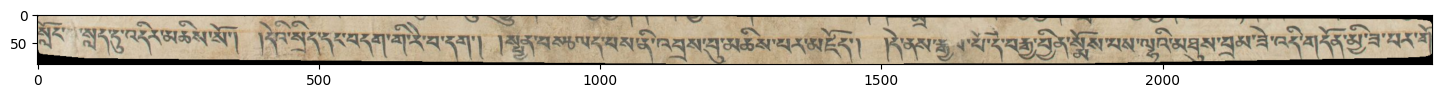

In [52]:
show_image(line_images[-1])

In [28]:
line_img = line_images[-1]
t_img = prepare_ocr_image(line_img)
t_img = tf.expand_dims(t_img, axis=-1)
print(t_img.shape)

out = predict_ocr(t_img)
print(out)

(2000, 80, 1)
(2000, 80, 1)


InvalidArgumentError: Graph execution error:

Detected at node model_1/conv1d/Conv1D defined at (most recent call last):
  File "C:\Users\Eric\AppData\Local\Programs\Python\Python310\lib\runpy.py", line 196, in _run_module_as_main

  File "C:\Users\Eric\AppData\Local\Programs\Python\Python310\lib\runpy.py", line 86, in _run_code

  File "d:\Github\OCR-Inference\venv\lib\site-packages\ipykernel_launcher.py", line 17, in <module>

  File "d:\Github\OCR-Inference\venv\lib\site-packages\traitlets\config\application.py", line 1075, in launch_instance

  File "d:\Github\OCR-Inference\venv\lib\site-packages\ipykernel\kernelapp.py", line 739, in start

  File "d:\Github\OCR-Inference\venv\lib\site-packages\tornado\platform\asyncio.py", line 205, in start

  File "C:\Users\Eric\AppData\Local\Programs\Python\Python310\lib\asyncio\base_events.py", line 603, in run_forever

  File "C:\Users\Eric\AppData\Local\Programs\Python\Python310\lib\asyncio\base_events.py", line 1909, in _run_once

  File "C

In [74]:
def read_tf_image_v1(img_path: str):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_jpeg(img, channels=1)
    img = tf.image.resize_with_pad(img, 80, 2000)

    return img.numpy(), img

4147


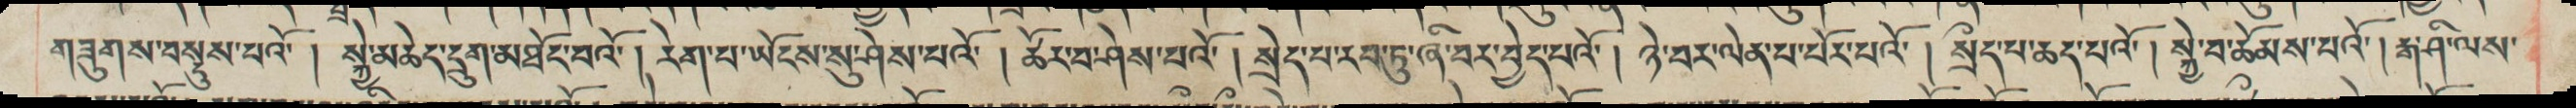

In [45]:
ds_lines = natsorted(glob(f"D:\Datasets\Tibetan\Glomanthang\Annotations_v2\Glomanthang-Annotations\Dataset_January2024_merged\lines\*.jpg"))
print(len(ds_lines))
test_img = ds_lines[123]
ShowImage(test_img)

In [83]:
from Utils import resize_to_width, pad_image2

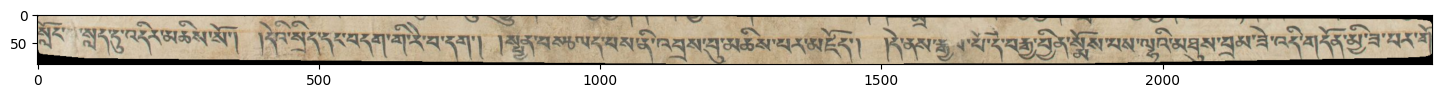

In [155]:
line_img = line_images[-1].copy()

show_image(line_img)

(80, 2000)
(2000, 80)
(1, 2000, 80)


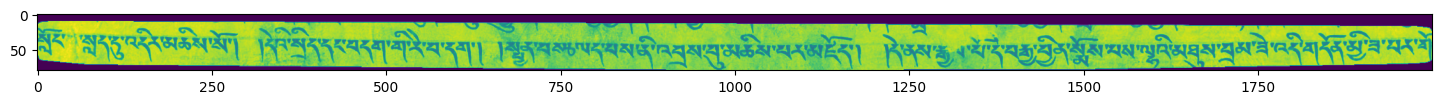

In [154]:
line_img = line_images[-1].copy()
line_img = resize_to_width(line_img, target_width=2000)
line_img = cv2.cvtColor(line_img, cv2.COLOR_RGB2GRAY)
line_img = pad_image2(line_img, target_width=2000, target_height=80, padding="black")
#line_img = tf.image.decode_jpeg(img, channels=1)
#line_img = tf.image.resize_with_pad(line_img, 80, 2000)
#line_img = line_img.numpy()
print(line_img.shape)
show_image(line_img)

line_img = np.transpose(line_img, axes=[1, 0])
print(line_img.shape)
line_img = np.expand_dims(line_img, axis=0)
line_img = tf.cast(line_img, tf.float32) / 255.0

print(line_img.shape)

(80, 2000, 1)


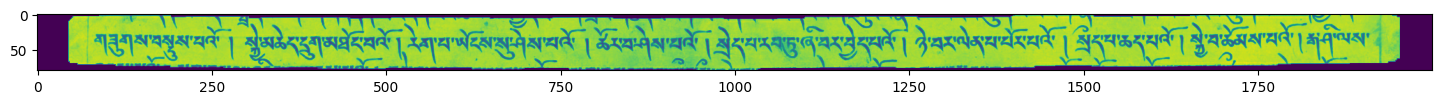

In [76]:
np_img, tf_img = read_tf_image_v1(test_img)
print(np_img.shape)
show_image(tf_img)

In [151]:
def read_tf_image(img_path: str):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_jpeg(img, channels=1)
    img = tf.image.resize_with_pad(img, 80, 2000)
    img = tf.cast(img, tf.float32) / 255.0
    img = tf.transpose(img, perm=[2, 1, 0])

    return img

tf_img = read_tf_image("ocr_test_line.jpg")
print(tf_img.shape)
out = predict_ocr(tf_img)
filtered_out= np.delete(out, np.where(out == -1))
filtered_list = filtered_out.tolist()
print(filtered_list)
decoded = "".join(model_chars[x] for x in filtered_list)
#decoded = decoded.replace("§", " ")
print(decoded)



(1, 2000, 80)
(1, 2000, 80)
1/1 [==============================] - 0s 472ms/step
[]



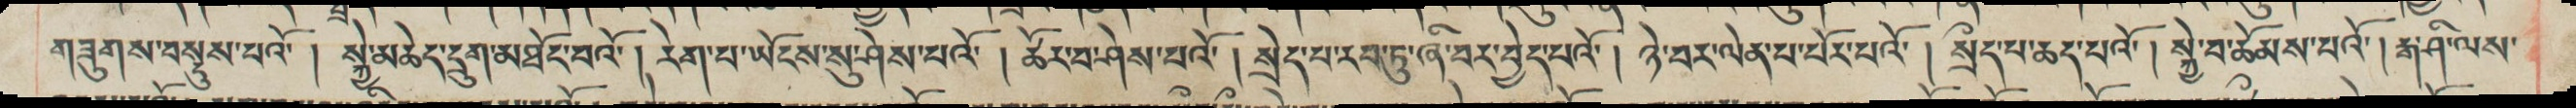

In [153]:
ShowImage(ds_lines[123])

(80, 2000, 3)


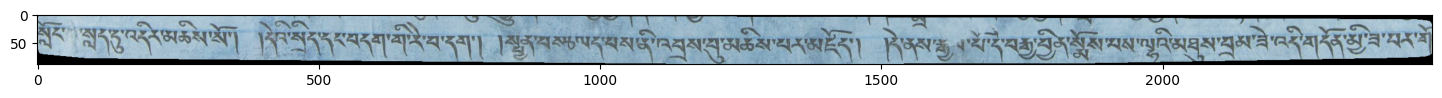

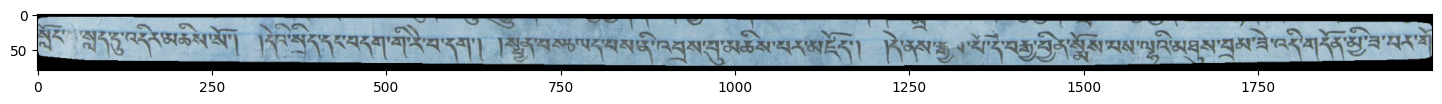

In [150]:
show_image(cv_img)

cv_img = tf.cast(cv_img, tf.float32)
cv_img = tf.image.resize_with_pad(cv_img, 80, 2000)
print(cv_img.shape)
show_image(np.array(cv_img, dtype=int))

(65, 1848, 3)


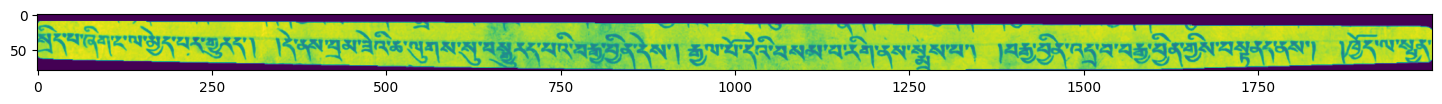

In [143]:
line_img = line_images[-2].copy()
line_img = resize_to_width(line_img, target_width=1848)
print(line_img.shape)
line_img = cv2.cvtColor(line_img, cv2.COLOR_RGB2GRAY)
line_img = pad_image2(line_img, target_width=2000, target_height=80, padding="black")

show_image(line_img)

(1, 2000, 80)


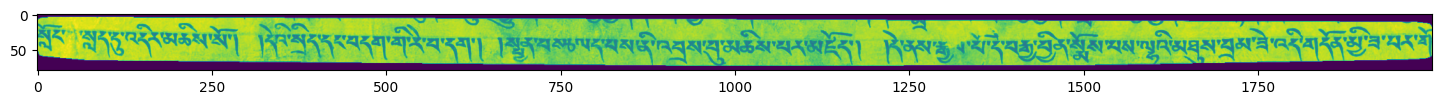

In [139]:
#cv2_img = cv2.cvtColor(cv_img, cv2.COLOR_BGR2GRAY)
cv_img = tf.image.rgb_to_grayscale(cv_img)
cv_img = cv_img / 255.0
show_image(cv_img)

cv_img = tf.transpose(cv_img, perm=[2, 1, 0])
print(cv_img.shape)

In [136]:
out = predict_ocr(cv_img)
filtered_out= np.delete(out, np.where(out == -1))
filtered_list = filtered_out.tolist()
print(filtered_list)
decoded = "".join(model_chars[x] for x in filtered_list)
#decoded = decoded.replace("§", " ")
print(decoded)

(1, 2000, 80)
1/1 [==============================] - 0s 261ms/step
[]



In [30]:
filtered_out= np.delete(out, np.where(out == -1))
filtered_list = filtered_out.tolist()
print(filtered_list)
decoded = "".join(model_chars[x] for x in filtered_list)
#decoded = decoded.replace("§", " ")
print(decoded)

[68, 11, 49, 60, 68, 44, 60, 46, 62, 60, 68, 58, 43, 4, 57, 68, 11, 60, 53, 64, 47, 68, 55, 45, 50, 47, 56, 49, 68, 46, 62, 49, 68, 55, 61, 50, 57, 56, 49, 68, 44, 43, 4, 57, 68, 11, 59, 51, 49, 68, 58, 43, 68, 64, 57, 56, 49, 60, 68, 60, 62, 68, 55, 47, 60, 68, 58, 43, 4, 57, 68, 11, 45, 50, 47, 59, 68, 58, 43, 68, 60, 50, 47, 60, 68, 58, 43, 4, 57, 68, 11, 60, 47, 46, 68, 58, 43, 68, 59, 43, 44, 68, 61, 62, 68, 54, 51, 68, 44, 43, 59, 68, 44, 64, 47, 46, 68, 58, 43, 4, 57, 68, 11, 56, 64, 47, 68, 44, 43, 59, 68, 54, 47, 56, 68, 58, 43, 68, 60, 57, 59, 68, 58, 43, 4, 57, 68, 60, 43, 46, 68, 58, 43, 68, 45, 50, 47, 46, 68, 58, 43, 4, 57, 68, 60, 53, 64, 47, 68, 44, 43, 68, 45, 60, 50, 43, 55, 60, 68, 58, 43]
&0ht&ctewt&rb`p&0tlzf&ndifoh&ewh&nuipoh&cb`p&0sjh&rb&zpoht&tw&nft&rb`p&0difs&rb&tift&rb`p&0tfe&rb&sbc&uw&mj&cbs&czfe&rb`p&0ozf&cbs&mfo&rb&tps&rb`p&tbe&rb&dife&rb`p&tlzf&cb&dtibnt&rb
